# LM5 Lab — Integration

Companion notebook to **From Calculus to Kelly, LM5**. It rebuilds the module's exhibits and computational examples from verified price files and solves the computational practice problems. Each part ends with `check(...)` lines that compare a computed value with the number printed in the module, at the printed precision, and stop the notebook if they differ.

| Part | Rebuilds |
|:--|:--|
| 1 | 0050 total returns (dividends, 4-for-1 split, trading days common with 00631L), verified against FinMind's `spread` |
| 2 | Riemann sums for a rising deposit rate and their error orders (Example 1, Exhibit 2) |
| 3 | The fundamental theorem, substitution and parts: exact accumulation, tail sensitivity, LM2's forward curve (Examples 2–4) |
| 4 | Improper integrals: the Gaussian integral, power-tail moments, sample-kurtosis instability (Example 5, Exhibit 4) |
| 5 | Continuous cash flows: rent as Riemann sums, duration, the compounding-convention pitfall (Example 6) |
| 6 | The normal model against 0050's tails: the nine days, thresholds, Mills bounds, tail means, lognormal mean (Exhibits 1, 6, 7; Examples 7–9) |
| 7 | Numerical integration: trapezoid vs Simpson error ratios, Richardson, whole-line trapezoid, `scipy.integrate.quad` (Example 10, Exhibit 8) |
| 8 | Computational practice problems and an extension exercise |

**Data.** `data/` holds a snapshot of FinMind `TaiwanStockPrice` closes for 0050 and 00631L (2014-10-31 → 2026-10-08) and 0050's cash dividends from `TaiwanStockDividendResult`, retrieved 2026-10-10. Every close was checked against FinMind's own `spread` column (close − previous close); the only mismatches are ex-dividend and split days, which Part 1 handles explicitly.

**Environment.** `uv pip install polars pyarrow numpy scipy matplotlib`.

In [1]:
from pathlib import Path
import math
import numpy as np
import polars as pl
import matplotlib.pyplot as plt
from scipy import integrate, special, stats

DATA = Path("data")
pl.Config.set_tbl_rows(30)
plt.rcParams.update({"figure.figsize": (9, 4.5), "axes.grid": True, "grid.alpha": 0.3,
                     "axes.spines.top": False, "axes.spines.right": False})

def check(label, value, printed, fmt):
    # Stop if `value`, formatted with `fmt`, differs from the string printed in the module.
    got = format(value, fmt)
    assert got == printed, f"{label}: computed {got}, module prints {printed}"
    print(f"ok  {label:<44s} {got}")

Phi = lambda z: 0.5 * special.erfc(-z / math.sqrt(2.0))      # accurate far into the tail
phi = lambda z: np.exp(-0.5 * np.asarray(z) ** 2) / math.sqrt(2 * math.pi)

## Part 1 — Total-return series, corporate actions, verification

On an ex-dividend date the total return is $R_t=(P_t+D_t)/P_{t-1}-1$. 0050 split 4-for-1 effective **2025-06-18** and 00631L 22-for-1 effective **2026-03-31**; on a split day the return is $P_t/(P_{t-1}/k)-1$. As in LM3 and LM4, the book's standard series uses the trading days common to both funds, which gives 2,902 daily returns.

In [2]:
SPLITS = {"0050": ("2025-06-18", 4), "00631L": ("2026-03-31", 22)}
div = pl.read_csv(DATA / "0050_dividends.csv")

def load_raw(sym):
    df = pl.read_csv(DATA / f"{sym}_daily_raw.csv").sort("date")
    gap = (pl.col("close") - pl.col("close").shift(1) - pl.col("spread")).abs()
    bad = df.with_columns(gap.alias("gap")).filter(pl.col("gap") > 0.005)
    expected = (set(div["date"].to_list()) if sym == "0050" else set()) | {SPLITS[sym][0]}
    unexplained = set(bad["date"].to_list()) - expected
    print(f"{sym}: {df.height} closes, checksum mismatches {bad.height}, unexplained {sorted(unexplained)}")
    assert not unexplained
    return df

def with_actions(sym):
    df = load_raw(sym)
    sd, k = SPLITS[sym]
    d = div.select("date", pl.col("cash_dividend").alias("D")) if sym == "0050" else \
        pl.DataFrame({"date": [], "D": []}, schema={"date": pl.Utf8, "D": pl.Float64})
    return (df.join(d, on="date", how="left")
              .with_columns(pl.col("D").fill_null(0.0),
                            pl.when(pl.col("date") == sd).then(k).otherwise(1).cast(pl.Float64).alias("split"))
              .select("date", pl.col("close").alias(f"P_{sym}"), pl.col("D").alias(f"D_{sym}"), pl.col("split").alias(f"S_{sym}")))

both = with_actions("0050").join(with_actions("00631L"), on="date", how="inner").sort("date")
ret = (both.with_columns(((pl.col("P_0050") + pl.col("D_0050")) / (pl.col("P_0050").shift(1) / pl.col("S_0050")) - 1).alias("R"))
           .drop_nulls("R").select("date", "R"))
R = ret["R"].to_numpy(); dates = ret["date"].to_list(); n = len(R)
years = (np.datetime64(dates[-1]) - np.datetime64("2014-10-31")).astype(int) / 365.25
D = n / years                                      # observations per year in this sample
mu, s = R.mean(), R.std()                          # population standard deviation, as in the module
print(n, dates[0], "->", dates[-1], f"years={years:.2f}  D={D:.1f}")
check("number of daily returns", n, "2902", "d")
check("mean daily return (%)", mu * 100, "0.0871", ".4f")
check("population sd (%)", s * 100, "1.2385", ".4f")
check("T-1 sd (%)", R.std(ddof=1) * 100, "1.2387", ".4f")
check("trading days per year", D, "243.1", ".1f")

0050: 2907 closes, checksum mismatches 23, unexplained []
00631L: 2908 closes, checksum mismatches 1, unexplained []
2902 2014-11-03 -> 2026-10-08 years=11.94  D=243.1
ok  number of daily returns                      2902
ok  mean daily return (%)                        0.0871
ok  population sd (%)                            1.2385
ok  T-1 sd (%)                                   1.2387
ok  trading days per year                        243.1


In [3]:
# Robustness: all 2,906 trading days of 0050 on their own (the common-day series merges four March 2026 days)
only = (with_actions("0050")
        .with_columns(((pl.col("P_0050") + pl.col("D_0050")) / (pl.col("P_0050").shift(1) / pl.col("S_0050")) - 1).alias("R"))
        .drop_nulls("R"))
Ro = only["R"].to_numpy()
for k in (-0.02, -0.03, -0.04, -0.05, -0.06, -0.07, -0.08, -0.09, -0.10):
    assert (Ro <= k + 1e-12).sum() == (R <= k + 1e-12).sum()
print(len(Ro), "returns; every threshold count of Exhibit 6 is unchanged")

0050: 2907 closes, checksum mismatches 23, unexplained []
2906 returns; every threshold count of Exhibit 6 is unchanged


## Part 2 — Riemann sums and their error orders (Example 1, Exhibit 2)

$r(t)=2.0\%-0.5\%\,e^{-2t}$ on $[0,1]$. The exact integral, from Section 3, is $2.0\%+0.25\%\,(e^{-2}-1)$.

In [4]:
r_t = lambda t: 0.02 - 0.005 * np.exp(-2 * np.asarray(t, dtype=float))
I1 = 0.02 + 0.0025 * (math.exp(-2) - 1)

def riemann(f, a, b, n):
    h = (b - a) / n; t = a + h * np.arange(n)
    return h * f(t).sum(), h * f(t + h).sum(), h * f(t + h / 2).sum()

rows = []
for nn in (4, 12, 365):
    L, Rr, M = riemann(r_t, 0, 1, nn)
    rows.append({"n": nn, "left_%": L * 100, "right_%": Rr * 100, "mid_%": M * 100,
                 "left_err_bp": (L - I1) * 1e4, "right_err_bp": (Rr - I1) * 1e4, "mid_err_bp": (M - I1) * 1e4})
tab = pl.DataFrame(rows)
print(tab)
check("exact accumulated rate (%)", I1 * 100, "1.783834", ".6f")
check("L4 (%)", rows[0]["left_%"], "1.7253", ".4f")
check("R4 (%)", rows[0]["right_%"], "1.8334", ".4f")
check("M4 error (bp)", rows[0]["mid_err_bp"], "0.224", ".3f")
check("M12 error (bp)", rows[1]["mid_err_bp"], "0.0250", ".4f")
check("L365 error (bp)", rows[2]["left_err_bp"], "-0.0593", ".4f")
check("NT$ exact", 1e6 * math.exp(I1), "1,017,998", ",.0f")
check("NT$ quarterly left", 1e6 * math.exp(rows[0]["left_%"] / 100), "1,017,403", ",.0f")
check("NT$ quarterly midpoint", 1e6 * math.exp(rows[0]["mid_%"] / 100), "1,018,021", ",.0f")

shape: (3, 7)
┌─────┬──────────┬──────────┬──────────┬─────────────┬──────────────┬────────────┐
│ n   ┆ left_%   ┆ right_%  ┆ mid_%    ┆ left_err_bp ┆ right_err_bp ┆ mid_err_bp │
│ --- ┆ ---      ┆ ---      ┆ ---      ┆ ---         ┆ ---          ┆ ---        │
│ i64 ┆ f64      ┆ f64      ┆ f64      ┆ f64         ┆ f64          ┆ f64        │
╞═════╪══════════╪══════════╪══════════╪═════════════╪══════════════╪════════════╡
│ 4   ┆ 1.725307 ┆ 1.833391 ┆ 1.786069 ┆ -5.852635   ┆ 4.955674     ┆ 0.223542   │
│ 12  ┆ 1.76532  ┆ 1.801348 ┆ 1.784084 ┆ -1.8514     ┆ 1.75137      ┆ 0.024999   │
│ 365 ┆ 1.783241 ┆ 1.784426 ┆ 1.783834 ┆ -0.059278   ┆ 0.05917      ┆ 0.000027   │
└─────┴──────────┴──────────┴──────────┴─────────────┴──────────────┴────────────┘
ok  exact accumulated rate (%)                   1.783834
ok  L4 (%)                                       1.7253
ok  R4 (%)                                       1.8334
ok  M4 error (bp)                                0.224
ok  M12 error 

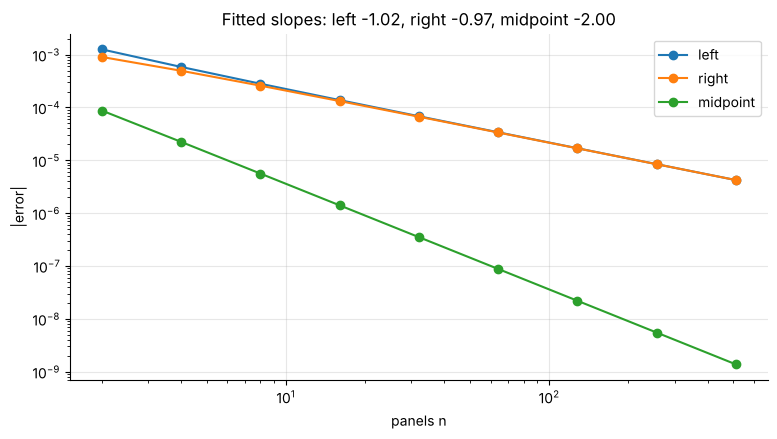

In [5]:
# Error against n on a log-log plot: slope -1 for left/right sums, -2 for midpoint sums
ns = np.array([2, 4, 8, 16, 32, 64, 128, 256, 512])
errs = np.array([[abs(v - I1) for v in riemann(r_t, 0, 1, int(k))] for k in ns])
fig, ax = plt.subplots()
for j, lab in enumerate(["left", "right", "midpoint"]):
    ax.loglog(ns, errs[:, j], "o-", label=lab)
slope = np.polyfit(np.log(ns), np.log(errs), 1)[0]
ax.set_xlabel("panels n"); ax.set_ylabel("|error|"); ax.legend()
ax.set_title(f"Fitted slopes: left {slope[0]:.2f}, right {slope[1]:.2f}, midpoint {slope[2]:.2f}")
plt.show()

## Part 3 — Fundamental theorem, substitution, parts (Examples 2–4)

In [6]:
k, z5 = -0.05, (-0.05 - mu) / s
p5 = Phi(z5)
# Example 2: elasticity of P = Phi((k - mu)/sigma) with respect to sigma
lam = phi(z5) / p5
el = -z5 * lam
p10 = Phi((k - mu) / (1.1 * s))
check("z for -5%", z5, "-4.1074", ".4f")
check("phi(z)/Phi(z)", lam, "4.3281", ".4f")
check("elasticity", el, "17.78", ".2f")
check("P with sigma +10%", p10 * 1e5, "9.422", ".3f")
check("ratio after +10%", p10 / p5, "4.71", ".2f")
check("expected days after +10%", n * p10, "0.27", ".2f")

# Example 3: the centre band, normal vs data
zu, zd = (0.01 - mu) / s, (-0.01 - mu) / s
check("Phi(0.7371)", Phi(zu), "0.76946", ".5f")
check("Phi(-0.8778)", Phi(zd), "0.19004", ".5f")
check("normal P(-1% < R <= 1%)", Phi(zu) - Phi(zd), "0.57943", ".5f")
check("data share in the band (%)", ((R > -0.01) & (R <= 0.01)).mean() * 100, "69.92", ".2f")

ok  z for -5%                                    -4.1074
ok  phi(z)/Phi(z)                                4.3281
ok  elasticity                                   17.78
ok  P with sigma +10%                            9.422
ok  ratio after +10%                             4.71
ok  expected days after +10%                     0.27
ok  Phi(0.7371)                                  0.76946
ok  Phi(-0.8778)                                 0.19004
ok  normal P(-1% < R <= 1%)                      0.57943
ok  data share in the band (%)                   69.92


In [7]:
# Example 4: integrate LM2's forward curve r(t) = 2% - 0.8% e^{-t/3} (1 - t/3) back into T*y(T)
import sympy as sp
t, T = sp.symbols("t T", positive=True)
r_fwd = sp.Rational(2, 100) - sp.Rational(8, 1000) * sp.exp(-t / 3) * (1 - t / 3)
acc = sp.simplify(sp.integrate(r_fwd, (t, 0, T)))
print("integral of r from 0 to T =", acc)          # T*(1/50 - exp(-T/3)/125), i.e. T*y(T)
for TT in (1, 5, 10):
    val = float(acc.subs(T, TT))
    num = integrate.quad(lambda x: 0.02 - 0.008 * math.exp(-x / 3) * (1 - x / 3), 0, TT)[0]
    print(TT, f"{val:.7f}  quad {num:.7f}  y(T) {val / TT:.5%}  P(T) {math.exp(-val):.6f}")
check("P(10)", math.exp(-float(acc.subs(T, 10))), "0.821071", ".6f")
check("t e^{-t/3} integral, T=5", float(sp.integrate(t * sp.exp(-t / 3), (t, 0, 5))), "4.466986", ".6f")

integral of r from 0 to T = T/50 - T*exp(-T/3)/125
1 0.0142677  quad 0.0142677  y(T) 1.42677%  P(T) 0.985834
5 0.0924450  quad 0.0924450  y(T) 1.84890%  P(T) 0.911699
10 0.1971461  quad 0.1971461  y(T) 1.97146%  P(T) 0.821071
ok  P(10)                                        0.821071
ok  t e^{-t/3} integral, T=5                     4.466986


## Part 4 — Improper integrals, the Gaussian integral, power tails (Example 5, Exhibit 4)

In [8]:
val, err = integrate.quad(lambda x: math.exp(-0.5 * x * x), -np.inf, np.inf)
print(f"Gaussian integral {val:.12f}  sqrt(2 pi) {math.sqrt(2 * math.pi):.12f}")
z_ = np.linspace(-12, 12, 200001)
print("variance of phi by trapezoid:", integrate.trapezoid(z_**2 * phi(z_), z_))

# Example 5: Pareto alpha = 3; truncated third and fourth moments diverge
alpha = 3.0
for b in (10, 100, 1000):
    m3 = integrate.quad(lambda x: x**3 * alpha * x ** (-alpha - 1), 1, b)[0]
    m4 = integrate.quad(lambda x: x**4 * alpha * x ** (-alpha - 1), 1, b)[0]
    print(b, f"{m3:.3f}", f"{m4:,.0f}")
check("3 ln 1000", 3 * math.log(1000), "20.723", ".3f")
for u, printed in ((0.03, "-4.42"), (0.05, "-6.54")):
    check(f"data mean beyond -{u:.0%} (%)", R[R <= -u + 1e-12].mean() * 100, printed, ".2f")
zu3 = (-0.03 - mu) / s
check("normal tail mean beyond -3% (%)", (mu - s * phi(zu3) / Phi(zu3)) * 100, "-3.40", ".2f")

Gaussian integral 2.506628274631  sqrt(2 pi) 2.506628274631
variance of phi by trapezoid: 1.0
10 6.908 27
100 13.816 297
1000 20.723 2,997
ok  3 ln 1000                                    20.723
ok  data mean beyond -3% (%)                     -4.42
ok  data mean beyond -5% (%)                     -6.54
ok  normal tail mean beyond -3% (%)              -3.40


ok  excess kurtosis, full sample                 8.12
ok  without 2025-04-07                           7.05
ok  without the four largest moves               3.85
ok  eve of 7 April 2025                          5.84
ok  after 7 April 2025                           7.63
ok  top-10 share of sum of 4th powers (%)        62.8
ok  top-10 share of sum of squares (%)           14.1


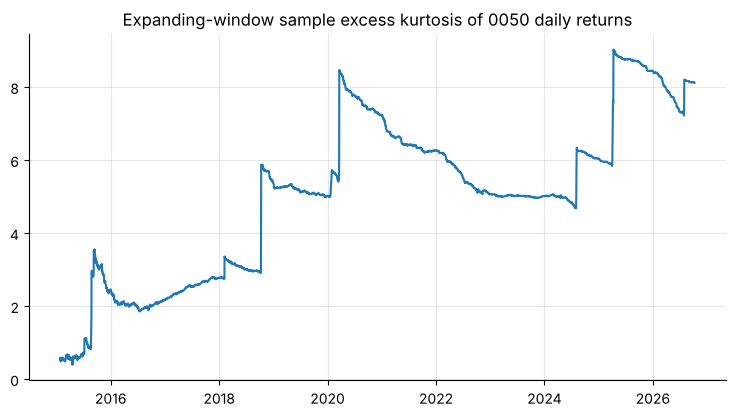

In [9]:
# Pitfall: the sample kurtosis never settles
def exkurt(x):
    return ((x - x.mean()) ** 4).mean() / x.std() ** 4 - 3

dr = ret.with_columns(pl.col("date").str.to_date().alias("d"))
check("excess kurtosis, full sample", exkurt(R), "8.12", ".2f")
check("without 2025-04-07", exkurt(dr.filter(pl.col("date") != "2025-04-07")["R"].to_numpy()), "7.05", ".2f")
big4 = ["2025-04-07", "2024-08-05", "2026-07-31", "2025-04-10"]
check("without the four largest moves", exkurt(dr.filter(~pl.col("date").is_in(big4))["R"].to_numpy()), "3.85", ".2f")
pre = np.array([d < "2025-04-07" for d in dates]); upto = np.array([d <= "2025-04-07" for d in dates])
check("eve of 7 April 2025", exkurt(R[pre]), "5.84", ".2f")
check("after 7 April 2025", exkurt(R[upto]), "7.63", ".2f")
dev4 = np.sort((R - mu) ** 4)[::-1]; dev2 = np.sort((R - mu) ** 2)[::-1]
check("top-10 share of sum of 4th powers (%)", dev4[:10].sum() / dev4.sum() * 100, "62.8", ".1f")
check("top-10 share of sum of squares (%)", dev2[:10].sum() / dev2.sum() * 100, "14.1", ".1f")

ek = [exkurt(R[: i + 1]) for i in range(60, n)]
fig, ax = plt.subplots()
ax.plot(np.array(dates[60:], dtype="datetime64[D]"), ek)
ax.set_title("Expanding-window sample excess kurtosis of 0050 daily returns"); plt.show()

## Part 5 — Continuous cash flows (Example 6)

Monthly payments are Riemann sums of $\int_0^T c\,e^{-rt}dt$: in arrears = right endpoints, in advance = left endpoints, mid-month = midpoints.

In [10]:
r0, T0, c = 0.02, 20, 360_000
k_ = np.arange(1, 241); h = 1 / 12
cont = c * (1 - math.exp(-r0 * T0)) / r0
arrears = (30_000 * np.exp(-r0 * k_ * h)).sum()
advance = (30_000 * np.exp(-r0 * (k_ - 1) * h)).sum()
middle = (30_000 * np.exp(-r0 * (k_ - 0.5) * h)).sum()
quadpv = integrate.quad(lambda t: c * math.exp(-r0 * t), 0, T0)[0]
check("continuous stream", cont, "5,934,239", ",.0f")
check("quad", quadpv, "5,934,239", ",.0f")
check("in arrears", arrears, "5,929,295", ",.0f")
check("in advance", advance, "5,939,186", ",.0f")
check("mid-month", middle, "5,934,238", ",.0f")
check("advance vs arrears (%)", (advance / arrears - 1) * 100, "0.167", ".3f")
D_ann = 1 / r0 - T0 / (math.exp(r0 * T0) - 1)
check("duration of the 20-year stream", D_ann, "9.335", ".3f")
r_eff = math.log1p(0.02)
check("PV with r = ln(1.02)", c * (1 - math.exp(-r_eff * T0)) / r_eff, "5,945,187", ",.0f")

ok  continuous stream                            5,934,239
ok  quad                                         5,934,239
ok  in arrears                                   5,929,295
ok  in advance                                   5,939,186
ok  mid-month                                    5,934,238
ok  advance vs arrears (%)                       0.167
ok  duration of the 20-year stream               9.335
ok  PV with r = ln(1.02)                         5,945,187


## Part 6 — The normal model against 0050's tails (Exhibits 1, 6, 7; Examples 7–9)

In [11]:
nine = ret.filter(pl.col("R") <= -0.05).with_columns(((pl.col("R") - mu) / s).alias("z"))
nine = nine.with_columns(pl.Series("P_normal", Phi(nine["z"].to_numpy())))      # no closed form: SciPy at the edge
nine = nine.with_columns((1 / (pl.col("P_normal") * D)).alias("years_between"))
print(nine)                                          # Exhibit 1
check("days at or below -5%", nine.height, "9", "d")
check("normal P(R <= -5%) x 1e5", p5 * 1e5, "2.0004", ".4f")
check("expected days", n * p5, "0.0581", ".4f")
check("return period (years)", 1 / (p5 * D), "205.6", ".1f")
check("actual / expected", nine.height / (n * p5), "155", ".0f")
check("mean of the nine (%)", nine["R"].mean() * 100, "-6.54", ".2f")

shape: (9, 5)
┌────────────┬───────────┬───────────┬────────────┬───────────────┐
│ date       ┆ R         ┆ z         ┆ P_normal   ┆ years_between │
│ ---        ┆ ---       ┆ ---       ┆ ---        ┆ ---           │
│ str        ┆ f64       ┆ f64       ┆ f64        ┆ f64           │
╞════════════╪═══════════╪═══════════╪════════════╪═══════════════╡
│ 2018-10-11 ┆ -0.07027  ┆ -5.744099 ┆ 4.6206e-9  ┆ 890229.718101 │
│ 2020-01-30 ┆ -0.056807 ┆ -4.657013 ┆ 0.000002   ┆ 2564.204728   │
│ 2020-03-19 ┆ -0.058379 ┆ -4.783985 ┆ 8.5927e-7  ┆ 4787.074775   │
│ 2022-10-11 ┆ -0.051789 ┆ -4.251892 ┆ 0.000011   ┆ 388.10608     │
│ 2024-04-19 ┆ -0.050645 ┆ -4.159506 ┆ 0.000016   ┆ 257.942946    │
│ 2024-08-02 ┆ -0.050543 ┆ -4.15132  ┆ 0.000017   ┆ 248.871133    │
│ 2024-08-05 ┆ -0.091299 ┆ -7.442029 ┆ 4.9575e-14 ┆ 8.2972e10     │
│ 2025-04-07 ┆ -0.1      ┆ -8.144534 ┆ 1.9037e-16 ┆ 2.1607e13     │
│ 2026-07-17 ┆ -0.058741 ┆ -4.813172 ┆ 7.4277e-7  ┆ 5537.904446   │
└────────────┴───────────┴────────

shape: (9, 7)
┌───────┬───────────┬────────────┬─────────────────┬────────┬─────────────┬───────────────┐
│ k     ┆ z         ┆ P_normal   ┆ expected_normal ┆ actual ┆ expected_t3 ┆ ratio         │
│ ---   ┆ ---       ┆ ---        ┆ ---             ┆ ---    ┆ ---         ┆ ---           │
│ f64   ┆ f64       ┆ f64        ┆ f64             ┆ i64    ┆ f64         ┆ f64           │
╞═══════╪═══════════╪════════════╪═════════════════╪════════╪═════════════╪═══════════════╡
│ -0.02 ┆ -1.685181 ┆ 0.045977   ┆ 133.42473       ┆ 104    ┆ 89.316246   ┆ 0.779466      │
│ -0.03 ┆ -2.4926   ┆ 0.006341   ┆ 18.400352       ┆ 37     ┆ 33.219178   ┆ 2.010831      │
│ -0.04 ┆ -3.300019 ┆ 0.000483   ┆ 1.4028          ┆ 18     ┆ 15.417267   ┆ 12.831483     │
│ -0.05 ┆ -4.107439 ┆ 0.00002    ┆ 0.05805         ┆ 9      ┆ 8.292473    ┆ 155.037928    │
│ -0.06 ┆ -4.914858 ┆ 4.4423e-7  ┆ 0.001289        ┆ 3      ┆ 4.940363    ┆ 2327.080544   │
│ -0.07 ┆ -5.722277 ┆ 5.2553e-9  ┆ 0.000015        ┆ 3      ┆ 3.16

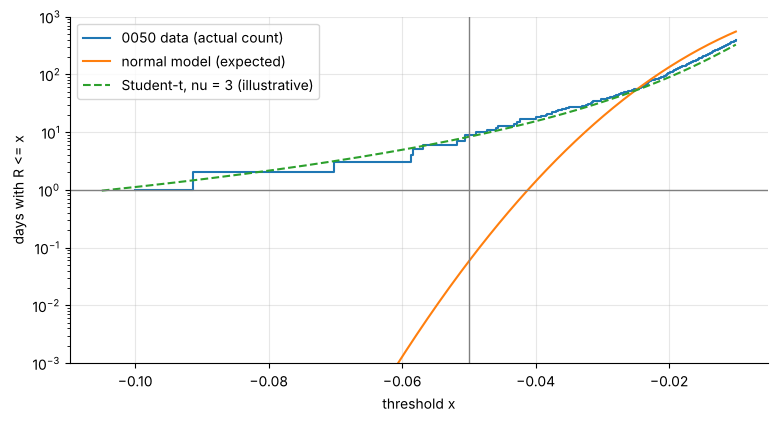

In [12]:
# Exhibit 6: thresholds, normal vs data vs an illustrative Student-t with nu = 3 and the same sd
nu = 3; sc = s * math.sqrt((nu - 2) / nu)
thr = pl.DataFrame({"k": [-0.02, -0.03, -0.04, -0.05, -0.06, -0.07, -0.08, -0.09, -0.10]})
kk = thr["k"].to_numpy()
thr = thr.with_columns(
    pl.Series("z", (kk - mu) / s),
    pl.Series("P_normal", Phi((kk - mu) / s)),
    pl.Series("expected_normal", n * Phi((kk - mu) / s)),
    pl.Series("actual", [int((R <= k + 1e-12).sum()) for k in kk]),
    pl.Series("expected_t3", n * stats.t.cdf((kk - mu) / sc, nu)),
).with_columns((pl.col("actual") / pl.col("expected_normal")).alias("ratio"))
print(thr)
check("t3 expected at -5%", thr["expected_t3"][3], "8.3", ".1f")
check("normal expected at -2%", thr["expected_normal"][0], "133.4", ".1f")

# Exhibit 7: counts on a log axis
x = np.linspace(-0.105, -0.01, 400)
fig, ax = plt.subplots()
srt = np.sort(R); cnt = np.arange(1, n + 1)
ax.step(srt[srt <= -0.01], cnt[srt <= -0.01], where="post", label="0050 data (actual count)")
ax.plot(x, n * Phi((x - mu) / s), label="normal model (expected)")
ax.plot(x, n * stats.t.cdf((x - mu) / sc, nu), "--", label="Student-t, nu = 3 (illustrative)")
ax.set_yscale("log"); ax.set_ylim(1e-3, 1e3); ax.axvline(-0.05, color="grey", lw=1); ax.axhline(1, color="grey", lw=1)
ax.set_xlabel("threshold x"); ax.set_ylabel("days with R <= x"); ax.legend(); plt.show()

In [13]:
# Example 7: Mills-ratio bracket (5.10) and Gordon's sharper lower bound
a = -z5; ph = float(phi(a))
check("phi(a) x 1e5", ph * 1e5, "8.6578", ".4f")
check("upper bound x 1e5", ph / a * 1e5, "2.1078", ".4f")
check("lower bound x 1e5", ph / a * (1 - 1 / a**2) * 1e5, "1.9829", ".4f")
print(f"Gordon lower bound {ph / (a + 1 / a):.4e}; exact {p5:.4e}")
# Example 8: tail mean (5.11)
check("normal E[R | R <= -5%] (%)", (mu - s * lam) * 100, "-5.27", ".2f")
# Example 9: lognormal mean (5.12) with annualized daily log-return moments
rl = np.log1p(R); m_a, v_a = rl.mean() * D, rl.var() * D
check("m (%)", m_a * 100, "19.31", ".2f")
check("sqrt v (%)", math.sqrt(v_a) * 100, "19.30", ".2f")
check("median growth (%)", (math.exp(m_a) - 1) * 100, "21.30", ".2f")
check("mean growth (%)", (math.exp(m_a + v_a / 2) - 1) * 100, "23.58", ".2f")
EG = integrate.quad(lambda x: math.exp(x - 0.5 * (x - m_a) ** 2 / v_a) / math.sqrt(2 * math.pi * v_a), -np.inf, np.inf)[0]
print(f"E[G] by quadrature {EG:.6f}")

ok  phi(a) x 1e5                                 8.6578
ok  upper bound x 1e5                            2.1078
ok  lower bound x 1e5                            1.9829
Gordon lower bound 1.9899e-05; exact 2.0004e-05
ok  normal E[R | R <= -5%] (%)                   -5.27
ok  m (%)                                        19.31
ok  sqrt v (%)                                   19.30
ok  median growth (%)                            21.30
ok  mean growth (%)                              23.58
E[G] by quadrature 1.235796


## Part 7 — Numerical integration (Example 10, Exhibit 8)

shape: (8, 6)
┌──────┬──────────┬───────────┬────────────┬────────────┬────────────┐
│ n    ┆ h        ┆ trap_err  ┆ trap_ratio ┆ simp_err   ┆ simp_ratio │
│ ---  ┆ ---      ┆ ---       ┆ ---        ┆ ---        ┆ ---        │
│ i64  ┆ f64      ┆ f64       ┆ f64        ┆ f64        ┆ f64        │
╞══════╪══════════╪═══════════╪════════════╪════════════╪════════════╡
│ 8    ┆ 0.98657  ┆ 0.000024  ┆ null       ┆ 0.00001    ┆ null       │
│ 16   ┆ 0.493285 ┆ 0.000007  ┆ 3.459871   ┆ 0.000001   ┆ 7.881503   │
│ 32   ┆ 0.246643 ┆ 0.000002  ┆ 3.840265   ┆ 9.4655e-8  ┆ 12.985536  │
│ 64   ┆ 0.123321 ┆ 4.4911e-7 ┆ 3.95838    ┆ 6.2306e-9  ┆ 15.192045  │
│ 128  ┆ 0.061661 ┆ 1.1257e-7 ┆ 3.989488   ┆ 3.9445e-10 ┆ 15.795627  │
│ 256  ┆ 0.03083  ┆ 2.8162e-8 ┆ 3.997365   ┆ 2.4732e-11 ┆ 15.948777  │
│ 512  ┆ 0.015415 ┆ 7.0416e-9 ┆ 3.999341   ┆ 1.5470e-12 ┆ 15.987186  │
│ 1024 ┆ 0.007708 ┆ 1.7605e-9 ┆ 3.999835   ┆ 9.6707e-14 ┆ 15.996802  │
└──────┴──────────┴───────────┴────────────┴────────────┴──────

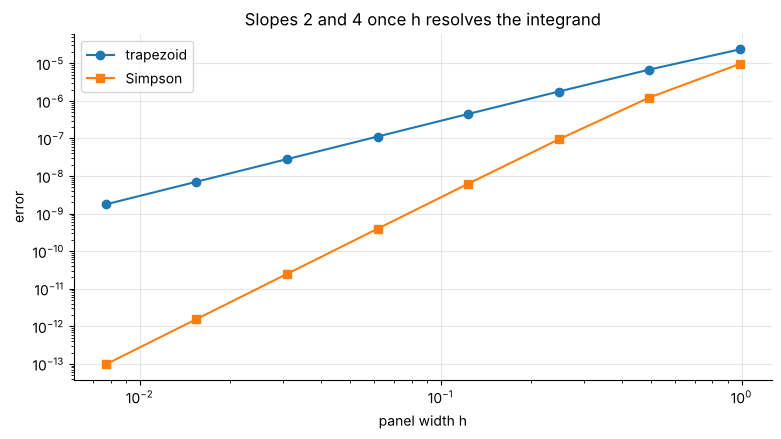

In [14]:
def trapezoid(f, a, b, n):
    x = np.linspace(a, b, n + 1); y = f(x); h = (b - a) / n
    return h * (y.sum() - 0.5 * (y[0] + y[-1]))

def simpson(f, a, b, n):
    x = np.linspace(a, b, n + 1); y = f(x); h = (b - a) / n
    return h / 3 * (y[0] + y[-1] + 4 * y[1:-1:2].sum() + 2 * y[2:-1:2].sum())

exact = p5 - Phi(-12.0)
rows, prev = [], None
for nn in (8, 16, 32, 64, 128, 256, 512, 1024):
    eT, eS = trapezoid(phi, -12, z5, nn) - exact, simpson(phi, -12, z5, nn) - exact
    rows.append({"n": nn, "h": (z5 + 12) / nn, "trap_err": eT, "trap_ratio": None if prev is None else prev[0] / eT,
                 "simp_err": eS, "simp_ratio": None if prev is None else prev[1] / eS})
    prev = (eT, eS)
ex8 = pl.DataFrame(rows)
print(ex8)                                           # Exhibit 8
check("trapezoid error n=256 x 1e8", rows[5]["trap_err"] * 1e8, "2.82", ".2f")
check("Simpson error n=1024 x 1e14", rows[7]["simp_err"] * 1e14, "9.67", ".2f")
check("trapezoid ratio n=16", rows[1]["trap_ratio"], "3.46", ".2f")
check("Simpson ratio n=1024", rows[7]["simp_ratio"], "16.00", ".2f")
h256 = rows[5]["h"]
check("(5.13) prediction n=256 x 1e8", h256**2 / 12 * (-z5 * float(phi(z5))) * 1e8, "2.817", ".3f")
check("Richardson (4T64-T32)/3 x 1e5", (4 * trapezoid(phi, -12, z5, 64) - trapezoid(phi, -12, z5, 32)) / 3 * 1e5, "2.0009784", ".7f")
check("Simpson S64 x 1e5", simpson(phi, -12, z5, 64) * 1e5, "2.0009784", ".7f")

fig, ax = plt.subplots()
ax.loglog(ex8["h"], ex8["trap_err"], "o-", label="trapezoid")
ax.loglog(ex8["h"], ex8["simp_err"], "s-", label="Simpson")
ax.set_xlabel("panel width h"); ax.set_ylabel("error"); ax.legend(); ax.set_title("Slopes 2 and 4 once h resolves the integrand"); plt.show()

In [15]:
# Whole-line trapezoid rule for sqrt(2 pi): far better than O(h^2), because every endpoint derivative vanishes
for hh in (2.0, 1.5, 1.0, 0.5):
    kk = np.arange(-int(40 / hh), int(40 / hh) + 1)
    print(hh, f"{hh * np.exp(-0.5 * (kk * hh) ** 2).sum() - math.sqrt(2 * math.pi):+.2e}")
qv, qe = integrate.quad(lambda t: float(phi(t)), -np.inf, z5)
print("quad:", qv, qe, " relative difference from erfc:", f"{abs(qv - p5) / p5:.1e}")
check("quad relative difference", abs(qv - p5) / p5 * 1e11, "6.7", ".1f")

2.0 +3.61e-02
1.5 +7.76e-04
1.0 +1.34e-08
0.5 +4.44e-16
quad: 2.000355318446267e-05 2.2183600358768839e-10  relative difference from erfc: 6.7e-11
ok  quad relative difference                     6.7


## Part 8 — Practice problems (computational) and an extension

In [16]:
print("PP1 ", f"{(1 - math.exp(-0.3)) / 0.03:.4f}", f"(year-end payments {sum(math.exp(-0.03 * k) for k in range(1, 11)):.4f})")
L4 = 0.25 * np.exp(0.25 * np.arange(4)).sum(); R4 = 0.25 * np.exp(0.25 * np.arange(1, 5)).sum()
print("PP2 ", f"L4={L4:.6f} R4={R4:.6f} exact={math.e - 1:.6f} T4={(L4 + R4) / 2:.6f} predicted T4 error={0.25**2 / 12 * (math.e - 1):.6f}")
print("PP4 ", f"{1 - math.exp(-0.5):.4f}")
print("PP5 ", f"{1 / 0.025:.0f} years")
print("PP7 ", f"E[X]={2.5 / 1.5:.4f} E[X^2]={2.5 / 0.5:.4f} Var={5 - (2.5 / 1.5) ** 2:.4f}")
a8 = (0.06 + 0.0005) / 0.015; ph8 = float(phi(a8))
print("PP8 ", f"z={-a8:.4f} upper={ph8 / a8:.4e} lower={ph8 / a8 * (1 - 1 / a8**2):.4e} exact={Phi(-a8):.4e} per year={Phi(-a8) * 243.1:.4f} every {1 / (Phi(-a8) * 243.1):.0f} years")
print("PP9 ", f"{Phi(-4):.4e}  two-sided {2 * Phi(-4):.4e}  Cantelli {1 / 17:.4f}")
print("PP10", f"PV={(1 - math.exp(-0.6)) / 0.02:.4f} forever={1 / 0.02:.1f} share={1 - math.exp(-0.6):.1%}")
g = lambda x: np.exp(-0.5 * x * x); I11 = math.sqrt(2 * math.pi) * (Phi(1) - 0.5)
print("PP11", f"T2={trapezoid(g, 0, 1, 2):.6f} T4={trapezoid(g, 0, 1, 4):.6f} S4={simpson(g, 0, 1, 4):.6f} exact={I11:.6f}")
print("PP13", f"mean={math.exp(0.10):.4f} median={math.exp(0.08):.4f} P(G<1)={Phi(-0.4):.4f}")
print("PP14", f"{-float(phi(2)) / Phi(-2):.4f}")
up = ret.filter(pl.col("R") >= 0.05)
print("PP15", up, f"expected {n * Phi(-(0.05 - mu) / s):.3f}")
z9 = stats.norm.ppf(9 / n); sig9 = (-0.05 - mu) / z9
print("PP16", f"sigma={sig9:.4%}  at -2%: {n * Phi((-0.02 - mu) / sig9):.0f}  at -3%: {n * Phi((-0.03 - mu) / sig9):.0f}")
check("PP16 sigma (%)", sig9 * 100, "1.8587", ".4f")

PP1  8.6394 (year-end payments 8.5104)
PP2  L4=1.512437 R4=1.942007 exact=1.718282 T4=1.727222 predicted T4 error=0.008949
PP4  0.3935
PP5  40 years
PP7  E[X]=1.6667 E[X^2]=5.0000 Var=2.2222
PP8  z=-4.0333 upper=2.9023e-05 lower=2.7239e-05 exact=2.7496e-05 per year=0.0067 every 150 years
PP9  3.1671e-05  two-sided 6.3342e-05  Cantelli 0.0588
PP10 PV=22.5594 forever=50.0 share=45.1%
PP11 T2=0.842881 T4=0.852459 S4=0.855651 exact=0.855624
PP13 mean=1.1052 median=1.0833 P(G<1)=0.3446
PP14 -2.3732
PP15 shape: (6, 2)
┌────────────┬──────────┐
│ date       ┆ R        │
│ ---        ┆ ---      │
│ str        ┆ f64      │
╞════════════╪══════════╡
│ 2020-03-20 ┆ 0.079504 │
│ 2022-11-11 ┆ 0.05314  │
│ 2024-08-06 ┆ 0.055118 │
│ 2025-04-10 ┆ 0.099863 │
│ 2026-04-08 ┆ 0.051793 │
│ 2026-07-31 ┆ 0.1      │
└────────────┴──────────┘ expected 0.106
PP16 sigma=1.8587%  at -2%: 379  at -3%: 140
ok  PP16 sigma (%)                               1.8587


### Extension: how much of the fat tail is changing volatility?

Section 7 notes that part of the gap comes from volatility that changes over time ([LM26]). Standardize each day's return by a volatility estimated only from the previous 60 days, $z_t=(R_t-\hat\mu)/\hat\sigma_{t-1}$, and count the days with $z_t\le-4.107$, the case's threshold in standard-deviation units. If volatility clustering explained everything, the count would be close to the normal model's 0.058. Try other windows (20, 120, 250 days) and an exponentially weighted estimate, and compare the counts with Exhibit 6.

In [17]:
roll = (ret.with_columns(pl.col("R").rolling_std(window_size=60).shift(1).alias("sd60"))
           .drop_nulls("sd60")
           .with_columns(((pl.col("R") - mu) / pl.col("sd60")).alias("z")))
print(roll.height, "days with a trailing 60-day volatility")
print("days with z <= -4.107:", roll.filter(pl.col("z") <= z5).height,
      " normal expectation:", f"{roll.height * Phi(z5):.3f}")
roll.sort("z").head(10)

2842 days with a trailing 60-day volatility
days with z <= -4.107: 8  normal expectation: 0.057


date,R,sd60,z
str,f64,f64,f64
"""2018-10-11""",-0.07027,0.007724,-9.211005
"""2025-04-07""",-0.1,0.013368,-7.545714
"""2020-01-30""",-0.056807,0.007724,-7.467312
"""2018-02-06""",-0.047249,0.007169,-6.712312
"""2024-08-05""",-0.091299,0.016814,-5.481749
"""2022-10-11""",-0.051789,0.012156,-4.331926
"""2024-04-19""",-0.050645,0.012242,-4.208267
"""2015-08-24""",-0.038462,0.009488,-4.145531
"""2020-03-19""",-0.058379,0.014638,-4.047598
